<a href="https://colab.research.google.com/github/gopisardhana4674-cloud/AI-Recipe/blob/main/InternalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/sales_transactions_regression.csv")
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


#information of dataset

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  249 non-null    object 
 1   region          245 non-null    object 
 2   product_id      239 non-null    float64
 3   product_id.1    239 non-null    float64
 4   sales_amount    249 non-null    float64
 5   date            248 non-null    object 
 6   units_sold      241 non-null    float64
 7   unit_price      239 non-null    float64
 8   discount_pct    244 non-null    float64
 9   store_id        249 non-null    object 
 10  product_id.2    239 non-null    float64
 11  product_id.3    239 non-null    float64
dtypes: float64(8), object(4)
memory usage: 24.5+ KB


In [8]:

df.head()


,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0


#Checking missing values

In [9]:

df.isnull().sum()

,0
transaction_id,11
region,15
product_id,21
product_id.1,21
sales_amount,11
date,12
units_sold,19
unit_price,21
discount_pct,16
store_id,11


In [10]:

(df.isnull().mean() * 100).round(2)


,0
transaction_id,4.23
region,5.77
product_id,8.08
product_id.1,8.08
sales_amount,4.23
date,4.62
units_sold,7.31
unit_price,8.08
discount_pct,6.15
store_id,4.23


In [11]:
(df.isnull().mean() * 100).round(2)

,0
transaction_id,4.23
region,5.77
product_id,8.08
product_id.1,8.08
sales_amount,4.23
date,4.62
units_sold,7.31
unit_price,8.08
discount_pct,6.15
store_id,4.23


In [12]:
df_clean = df.copy()

#Handle Missing Values in Target Column

In [13]:
df_clean.dropna(subset=['sales_amount'], inplace=True)

In [14]:
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


#Handle Missing Values in Numerical Columns

In [15]:
df_clean['units_sold'] = df_clean['units_sold'].fillna(df_clean['units_sold'].median())

df_clean['unit_price'] = df_clean['unit_price'].fillna(df_clean['unit_price'].median())

df_clean['discount_pct'] = df_clean['discount_pct'].fillna(df_clean['discount_pct'].median())

In [16]:
df_clean[['units_sold', 'unit_price', 'discount_pct']].isnull().sum()

,0
units_sold,0
unit_price,0
discount_pct,0


In [17]:
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


#Analyze Unique Values in Region

In [18]:
df_clean['region'].value_counts()

,count
region,
West,51
East,46
North,44
South,41
EAST,8
WEST,8
SOUTH,6
NORTH,5
Wet,4


In [19]:
region_mapping = {
    'WEST': 'West',
    'Wet': 'West',
    'Wst': 'West',
    'Wes': 'West',
    'est': 'West',
    'EAST': 'East',
    'Eat': 'East',
    'ast': 'East',
    'Eas': 'East',
    'NORTH': 'North',
    'Nort': 'North',
    'Noth': 'North',
    'orth': 'North',
    'Norh': 'North',
    'Nrth': 'North',
    'SOUTH': 'South',
    'Soth': 'South'
}

df_clean['region'] = df_clean['region'].replace(region_mapping)

In [20]:
df_clean['region'].value_counts()

,count
region,
West,69
East,59
North,56
South,50


In [22]:
df_clean['region'] = df_clean['region'].fillna(df_clean['region'].mode()[0])

In [23]:
df_clean['region'].isnull().sum()

np.int64(0)

#Analyze Missing Values in Remaining Columns

In [24]:
df_clean.isnull().sum()

,0
transaction_id,11
region,0
product_id,21
product_id.1,21
sales_amount,0
date,12
units_sold,0
unit_price,0
discount_pct,0
store_id,9


#Check Duplicate Records

In [25]:
df_clean.duplicated().sum()

np.int64(10)

#Remove Duplicate Records

In [26]:
df_clean.drop_duplicates(inplace=True)

In [27]:
df_clean.duplicated().sum()

np.int64(0)

#Checking the Updated Dataset Shape

In [28]:
df_clean.shape

(239, 12)

#Checking Duplicate Transaction IDs

In [29]:
df_clean['transaction_id'].dropna().duplicated().sum()

np.int64(0)

In [30]:
df_clean[['transaction_id', 'product_id', 'store_id']].isnull().sum()

,0
transaction_id,10
product_id,19
store_id,8


In [31]:
df_clean[['product_id', 'product_id.1', 'product_id.2', 'product_id.3']].head(10)

,product_id,product_id.1,product_id.2,product_id.3
0,426.0,426.0,426.0,426.0
1,394.0,394.0,394.0,394.0
2,446.0,446.0,446.0,446.0
3,136.0,136.0,136.0,136.0
4,287.0,287.0,287.0,287.0
5,436.0,436.0,436.0,436.0
6,487.0,487.0,487.0,487.0
7,122.0,122.0,122.0,122.0
8,497.0,497.0,497.0,497.0
9,360.0,360.0,360.0,360.0


In [32]:
df_clean['product_id'].equals(df_clean['product_id.1']) and df_clean['product_id'].equals(df_clean['product_id.2']) and df_clean['product_id'].equals(df_clean['product_id.3'])

True

In [33]:
df_clean.drop(
    columns=['product_id.1', 'product_id.2', 'product_id.3'],
    inplace=True
)

In [34]:
df_clean.columns

Index(['transaction_id', 'region', 'product_id', 'sales_amount', 'date',
       'units_sold', 'unit_price', 'discount_pct', 'store_id'],
      dtype='object')

#Convert Date Column into Datetime Format

In [35]:
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')

In [36]:
df_clean['date'].dtype

dtype('<M8[ns]')

In [37]:
df_clean['date'].isnull().sum()

np.int64(12)

In [38]:
df_clean.dropna(subset=['date'], inplace=True)

In [39]:
df_clean['date'].isnull().sum()

np.int64(0)

#Checking remaining missing values

In [40]:
df_clean.isnull().sum()

,0
transaction_id,10
region,0
product_id,18
sales_amount,0
date,0
units_sold,0
unit_price,0
discount_pct,0
store_id,7


In [41]:
df_clean[df_clean[['transaction_id', 'product_id', 'store_id']].isnull().any(axis=1)]

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
15,T50015,East,NaN,2880.7800,2024-01-16,6.0,480.13,0.00,S2
18,T50018,North,NaN,140.2176,2024-01-19,3.0,69.76,0.33,S1
19,T50019,East,NaN,338.7060,2024-01-20,5.0,72.84,0.07,S2
21,T50021,West,467.0,1067.1891,2024-01-22,3.0,235.70,0.17,NaN
42,T50042,North,NaN,352.7874,2024-02-12,5.0,235.70,0.49,S1
47,NaN,North,NaN,1724.7888,2024-02-17,6.0,404.88,0.29,S3
56,T50056,East,468.0,754.0182,2024-02-26,3.0,364.26,0.23,NaN
58,NaN,East,376.0,1110.1212,2024-02-28,4.0,235.70,0.19,S2
66,NaN,South,414.0,1686.3693,2024-03-07,7.0,312.87,0.23,S
70,T50070,South,151.0,385.9641,2024-03-11,3.0,225.71,0.43,NaN


In [42]:
df_clean['store_id'].unique()

array(['S2', 'S3', 'S4', 'S1', '2', nan, 'S', '1', '3'], dtype=object)

In [43]:
df_clean['store_id'].value_counts(dropna=False)

,count
store_id,
S2,59
S3,59
S1,40
S4,39
S,16
NaN,7
3,3
2,2
1,2


In [44]:
store_mapping = {
    '1': 'S1',
    '2': 'S2',
    '3': 'S3'
}

df_clean['store_id'] = df_clean['store_id'].replace(store_mapping)

In [45]:
df_clean['store_id'].value_counts(dropna=False)

,count
store_id,
S3,62
S2,61
S1,42
S4,39
S,16
NaN,7


In [46]:
df_clean[df_clean['store_id'] == 'S']

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
34,T50034,West,312.0,369.4698,2024-02-04,7.0,89.46,0.41,S
38,T50038,East,302.0,1638.2716,2024-02-08,7.0,254.39,0.08,S
64,T50064,West,162.0,649.7550,2024-03-05,6.0,235.70,0.25,S
66,NaN,South,414.0,1686.3693,2024-03-07,7.0,312.87,0.23,S
71,NaN,South,420.0,230.3700,2024-03-12,1.0,274.25,0.16,S
79,T50079,West,103.0,3952.2384,2024-03-20,9.0,499.02,0.12,S
81,T50081,West,389.0,593.2745,2024-03-22,7.0,99.71,0.15,S
85,T50085,West,454.0,2007.9948,2024-03-26,7.0,329.72,0.13,S
112,T50112,West,NaN,317.2700,2024-04-22,5.0,317.27,0.00,S
113,T50113,North,201.0,463.7250,2024-04-23,2.0,235.70,0.25,S


In [47]:
df_clean['store_id'] = df_clean['store_id'].replace('S', np.nan)

In [48]:
df_clean['store_id'].value_counts(dropna=False)

,count
store_id,
S3,62
S2,61
S1,42
S4,39
NaN,23


In [49]:
df_clean['store_id'] = df_clean['store_id'].fillna('Unknown')

In [50]:
df_clean['store_id'].isnull().sum()

np.int64(0)

In [51]:
df_clean[df_clean['transaction_id'].isnull()]

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
47,NaN,North,NaN,1724.7888,2024-02-17,6.0,404.88,0.29,S3
58,NaN,East,376.0,1110.1212,2024-02-28,4.0,235.70,0.19,S2
66,NaN,South,414.0,1686.3693,2024-03-07,7.0,312.87,0.23,Unknown
71,NaN,South,420.0,230.3700,2024-03-12,1.0,274.25,0.16,Unknown
126,NaN,East,240.0,2352.8330,2024-05-06,7.0,480.17,0.30,S4
145,NaN,West,330.0,396.1230,2024-05-25,5.0,217.65,0.09,S1
148,NaN,North,394.0,1166.4135,2024-05-28,5.0,370.29,0.37,S4
163,NaN,North,411.0,702.6675,2024-06-12,5.0,246.55,0.43,S3
192,NaN,West,157.0,1485.2135,2024-07-11,5.0,418.37,0.29,S2
220,NaN,North,339.0,1177.0850,2024-08-08,5.0,258.70,0.09,S2


In [52]:
df_clean[df_clean['transaction_id'].notnull()][['transaction_id']].head(15)

,transaction_id
0,T50000
1,T50001
2,T50002
3,T50003
4,T50004
5,T50005
6,T50006
7,T50007
8,T50008
9,T50009


In [53]:
valid = df_clean['transaction_id'].notna()

(
    df_clean.loc[valid, 'transaction_id']
    .str.extract(r'(\d+)$')[0]
    .astype(int)
    == df_clean.index[valid] + 50000
).all()

np.True_

In [54]:
mask = df_clean['transaction_id'].isnull()

df_clean.loc[mask, 'transaction_id'] = (
    'T' + (50000 + df_clean.index[mask]).astype(str)
)

In [55]:
df_clean['transaction_id'].isnull().sum()

np.int64(0)

In [57]:
df_clean['transaction_id'].duplicated().sum()

np.int64(0)

In [58]:
df_clean['product_id'] = df_clean['product_id'].astype('string')

df_clean['product_id'] = df_clean['product_id'].fillna('Unknown')

In [59]:
df_clean['product_id'].isnull().sum()

np.int64(0)

In [60]:
df_clean.isnull().sum()

,0
transaction_id,0
region,0
product_id,0
sales_amount,0
date,0
units_sold,0
unit_price,0
discount_pct,0
store_id,0


In [61]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 227 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  227 non-null    object        
 1   region          227 non-null    object        
 2   product_id      227 non-null    string        
 3   sales_amount    227 non-null    float64       
 4   date            227 non-null    datetime64[ns]
 5   units_sold      227 non-null    float64       
 6   unit_price      227 non-null    float64       
 7   discount_pct    227 non-null    float64       
 8   store_id        227 non-null    object        
dtypes: datetime64[ns](1), float64(4), object(3), string(1)
memory usage: 17.7+ KB


In [62]:
df_clean.describe(include='all')

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
count,227,227,227,227.000000,227,227.000000,227.00000,227.000000,227
unique,227,4,165,NaN,NaN,NaN,NaN,NaN,5
top,T50000,West,Unknown,NaN,NaN,NaN,NaN,NaN,S3
freq,1,74,18,NaN,NaN,NaN,NaN,NaN,62
mean,NaN,NaN,NaN,1001.904902,2024-04-30 09:30:55.506607872,5.277533,250.83022,0.240176,NaN
min,NaN,NaN,NaN,14.792400,2024-01-01 00:00:00,1.000000,5.16000,0.000000,NaN
25%,NaN,NaN,NaN,367.623650,2024-02-27 12:00:00,3.500000,141.70500,0.120000,NaN
50%,NaN,NaN,NaN,754.018200,2024-04-29 00:00:00,5.000000,235.70000,0.230000,NaN
75%,NaN,NaN,NaN,1474.440350,2024-06-30 12:00:00,7.000000,360.20000,0.345000,NaN
max,NaN,NaN,NaN,3952.238400,2024-09-06 00:00:00,9.000000,499.63000,0.490000,NaN


In [63]:
print("Negative sales amounts:")
print((df_clean['sales_amount'] < 0).sum())

print("\nZero or negative units sold:")
print((df_clean['units_sold'] <= 0).sum())

print("\nZero or negative unit prices:")
print((df_clean['unit_price'] <= 0).sum())

print("\nInvalid discount percentages:")
print(((df_clean['discount_pct'] < 0) |
       (df_clean['discount_pct'] > 1)).sum())

Negative sales amounts:
0

Zero or negative units sold:
0

Zero or negative unit prices:
0

Invalid discount percentages:
0


#Exploratory Data Analysis (EDA)

In [64]:
df_clean.describe()

,sales_amount,date,units_sold,unit_price,discount_pct
count,227.000000,227,227.000000,227.00000,227.000000
mean,1001.904902,2024-04-30 09:30:55.506607872,5.277533,250.83022,0.240176
min,14.792400,2024-01-01 00:00:00,1.000000,5.16000,0.000000
25%,367.623650,2024-02-27 12:00:00,3.500000,141.70500,0.120000
50%,754.018200,2024-04-29 00:00:00,5.000000,235.70000,0.230000
75%,1474.440350,2024-06-30 12:00:00,7.000000,360.20000,0.345000
max,3952.238400,2024-09-06 00:00:00,9.000000,499.63000,0.490000
std,831.699162,NaN,2.477791,137.21664,0.137071


#Analyze sales distribution

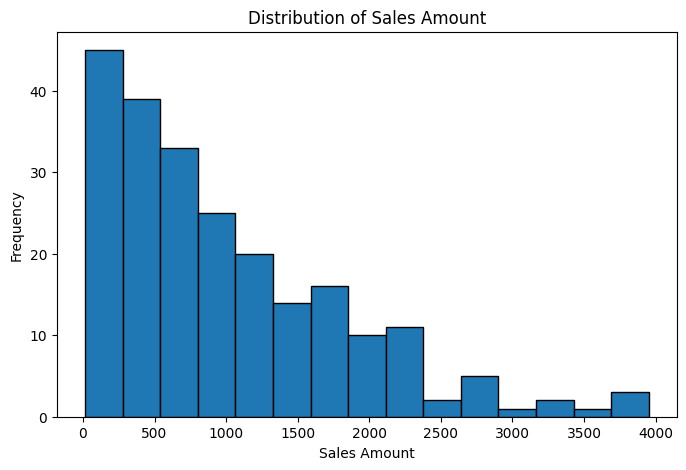

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean['sales_amount'], bins=15, edgecolor='black')

plt.title('Distribution of Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')

plt.show()

#Detect Outliers Using a Box Plot

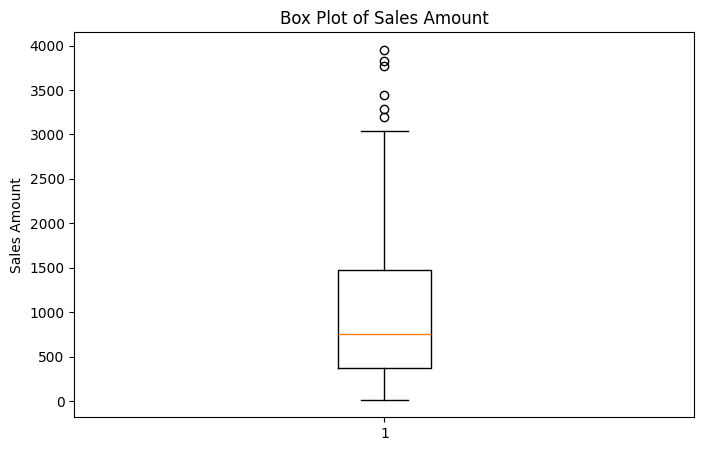

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(df_clean['sales_amount'])

plt.title('Box Plot of Sales Amount')
plt.ylabel('Sales Amount')

plt.show()

#Identify the Outlier Records

In [67]:
Q1 = df_clean['sales_amount'].quantile(0.25)
Q3 = df_clean['sales_amount'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[df_clean['sales_amount'] > upper_limit]

print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

outliers[['transaction_id', 'sales_amount', 'units_sold', 'unit_price', 'discount_pct']]

Upper Limit: 3134.6654
Number of Outliers: 6


,transaction_id,sales_amount,units_sold,unit_price,discount_pct
3,T50003,3439.5648,8.0,438.72,0.23
74,T50074,3821.4792,9.0,482.51,0.12
79,T50079,3952.2384,9.0,499.02,0.12
155,T50155,3771.1080,8.0,476.15,0.01
198,T50198,3190.9605,7.0,469.95,0.03
242,T50242,3281.0232,8.0,450.69,0.09


#Remove Outliers Using IQR Method

In [68]:
Q1 = df_clean['sales_amount'].quantile(0.25)
Q3 = df_clean['sales_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df_final = df_clean[
    (df_clean['sales_amount'] >= lower_limit) &
    (df_clean['sales_amount'] <= upper_limit)
].copy()

In [69]:
print("Original Dataset:", df_clean.shape)
print("Final Dataset:", df_final.shape)
print("Removed Records:", len(df_clean) - len(df_final))

Original Dataset: (227, 9)
Final Dataset: (221, 9)
Removed Records: 6


#Verify Outlier Removal

In [70]:
Q1 = df_final['sales_amount'].quantile(0.25)
Q3 = df_final['sales_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

remaining_outliers = df_final[
    (df_final['sales_amount'] < lower_limit) |
    (df_final['sales_amount'] > upper_limit)
]

print("Remaining Outliers:", len(remaining_outliers))

Remaining Outliers: 1


In [71]:
Q1 = df_final['sales_amount'].quantile(0.25)
Q3 = df_final['sales_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

remaining_outliers = df_final[
    (df_final['sales_amount'] < lower_limit) |
    (df_final['sales_amount'] > upper_limit)
]

remaining_outliers[['transaction_id', 'sales_amount', 'units_sold', 'unit_price', 'discount_pct']]

,transaction_id,sales_amount,units_sold,unit_price,discount_pct
89,T50089,3042.288,9.0,456.8,0.26


In [72]:
df_final = df_final.drop(index=89)

In [73]:
print("Final Dataset Shape:", df_final.shape)
print("Remaining Outlier Record:", (df_final['transaction_id'] == 'T50089').sum())

Final Dataset Shape: (220, 9)
Remaining Outlier Record: 0


#Final Dataset Validation

In [74]:
print("Dataset Shape:", df_final.shape)

print("\nMissing Values:")
print(df_final.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_final.duplicated().sum())

print("\nDuplicate Transaction IDs:")
print(df_final['transaction_id'].duplicated().sum())

Dataset Shape: (220, 9)

Missing Values:
0

Duplicate Rows:
0

Duplicate Transaction IDs:
0


#Export the Final Preprocessed CSV

In [93]:
df_final.to_csv(
    'final_preprocessed_sales_transactions.csv',
    index=False
)

In [76]:
import pandas as pd

check_df = pd.read_csv('final_preprocessed_sales_transactions.csv')

print("Exported Dataset Shape:", check_df.shape)
print("Missing Values:", check_df.isnull().sum().sum())
print("Duplicate Rows:", check_df.duplicated().sum())

Exported Dataset Shape: (220, 9)
Missing Values: 0
Duplicate Rows: 0


In [77]:
from google.colab import files

files.download('final_preprocessed_sales_transactions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Uploading preprocessed CSV File

In [78]:
import pandas as pd

df_final = pd.read_csv('final_preprocessed_sales_transactions.csv')

#**Univariate Analysis**

#Analyze Sales Amount Distribution

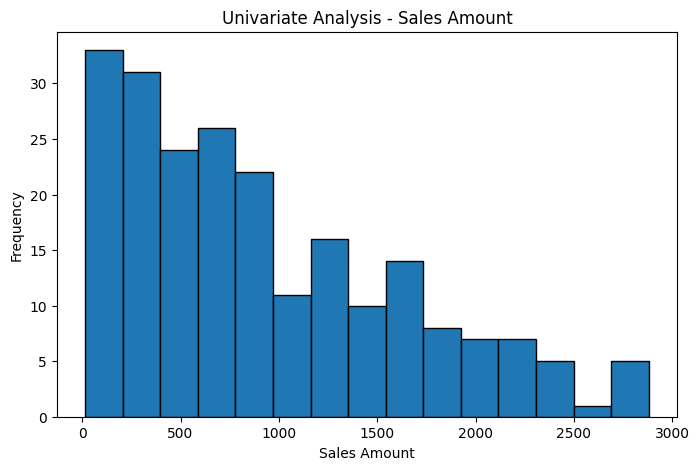

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_final['sales_amount'], bins=15, edgecolor='black')

plt.title('Univariate Analysis - Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')

plt.show()

#Analysis of Units Sold

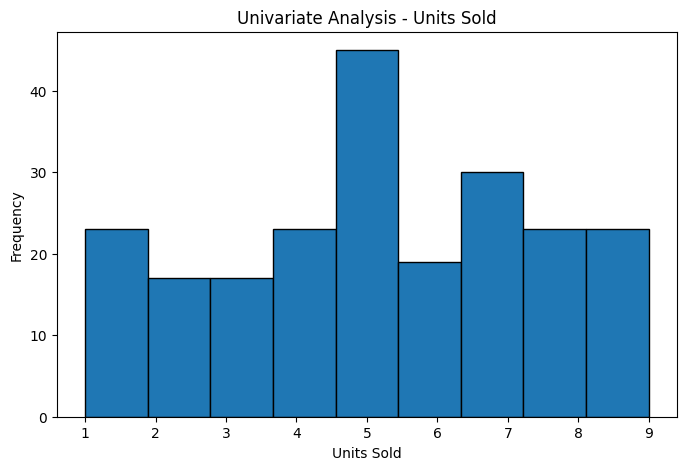

In [81]:
plt.figure(figsize=(8, 5))

plt.hist(df_final['units_sold'], bins=9, edgecolor='black')

plt.title('Univariate Analysis - Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Frequency')

plt.show()

#Observation
- Units sold range from 1 to 9
- 5 units has the highest frequency
- 7 units is also commonly purchased

#Analysis of Unit Price

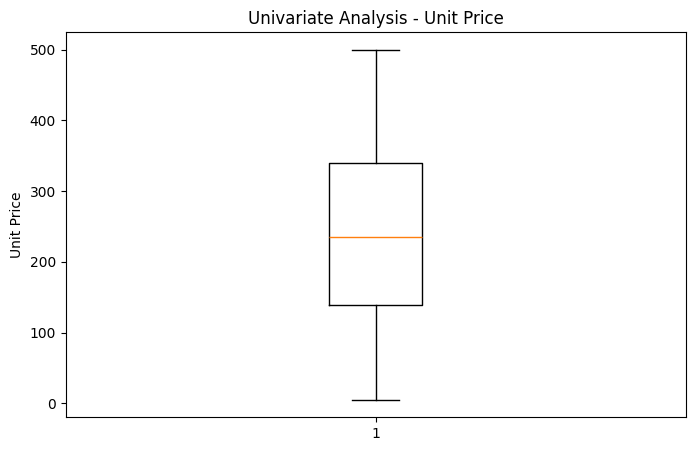

In [83]:
plt.figure(figsize=(8, 5))

plt.boxplot(df_final['unit_price'])

plt.title('Univariate Analysis - Unit Price')
plt.ylabel('Unit Price')

plt.show()

# Observation
- Unit prices range from approximately 5 to 500.
- The median unit price is around 235.
- Most prices are concentrated between 140 and 340.

#Analysis of Discount Percentage

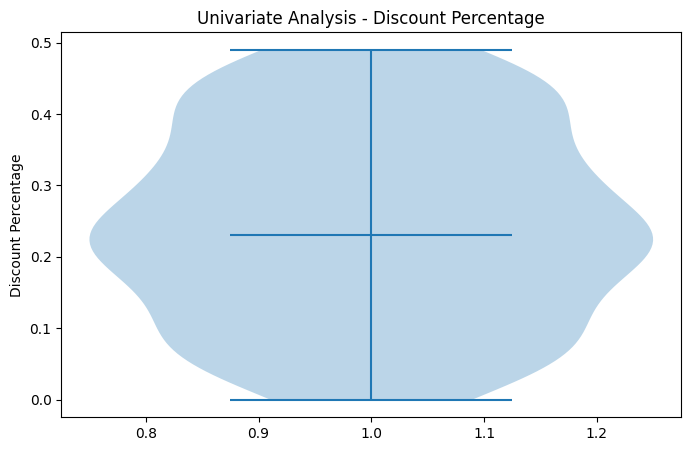

In [84]:
plt.figure(figsize=(8, 5))

plt.violinplot(df_final['discount_pct'], showmedians=True)

plt.title('Univariate Analysis - Discount Percentage')
plt.ylabel('Discount Percentage')

plt.show()

# Observation:
- Discount percentages range from 0% to 49%.
- The median discount is approximately 23%.
- Most discounts are concentrated around 20% to 25%.

#Analysis of Region

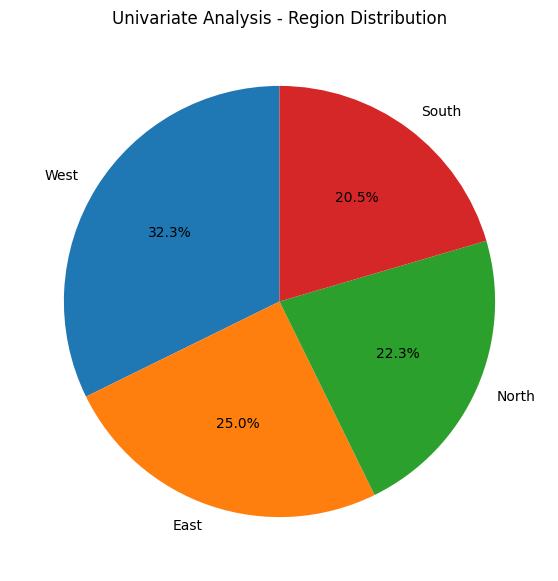

In [86]:
region_counts = df_final['region'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    region_counts,
    labels=region_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Univariate Analysis - Region Distribution')

plt.show()

# Observation:
- West has the highest transaction share at 32.3%.
- East contributes 25% of transactions.
- North accounts for 22.3%.

#**Bivariate**

#Units Sold vs Sales Amount

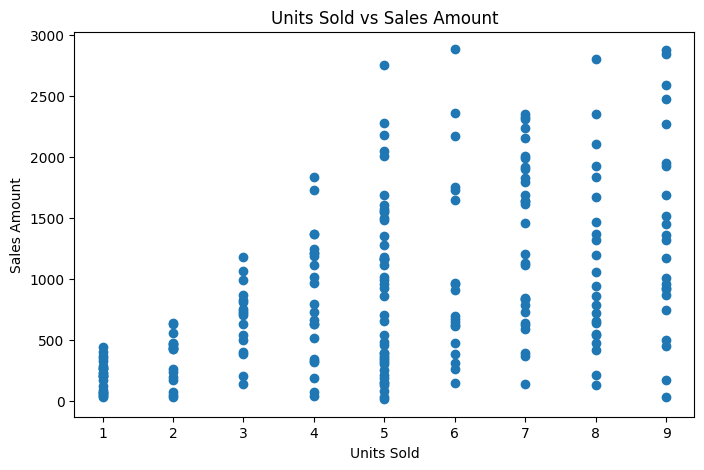

In [87]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_final['units_sold'],
    df_final['sales_amount']
)

plt.title('Units Sold vs Sales Amount')
plt.xlabel('Units Sold')
plt.ylabel('Sales Amount')

plt.show()

# Observation:
- Sales amount generally increases as units sold increase.
- Transactions with 1 unit have comparatively lower sales.
- Transactions with 7, 8, and 9 units show a wider range of sales values.

#Region vs Sales Amount

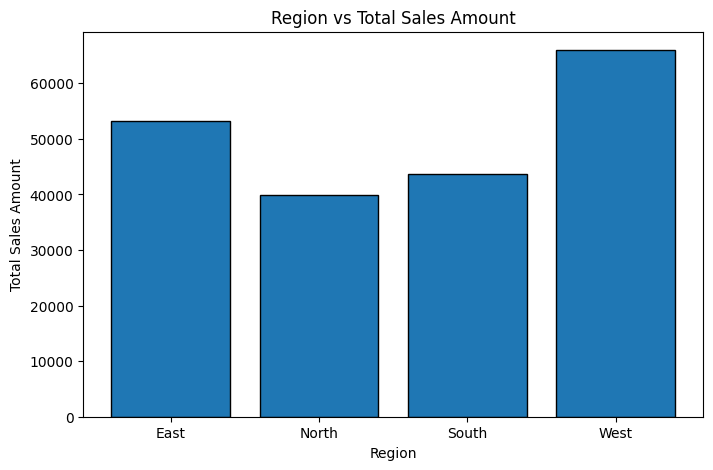

In [88]:
region_sales = df_final.groupby('region')['sales_amount'].sum()

plt.figure(figsize=(8, 5))

plt.bar(
    region_sales.index,
    region_sales.values,
    edgecolor='black'
)

plt.title('Region vs Total Sales Amount')
plt.xlabel('Region')
plt.ylabel('Total Sales Amount')

plt.show()

#Observation:
- West generates the highest total sales, approximately 66,000.
- East ranks second with around 53,000.
- South contributes approximately 44,000.

#Discount Percentage vs Sales Amount

<Figure size 900x500 with 0 Axes>

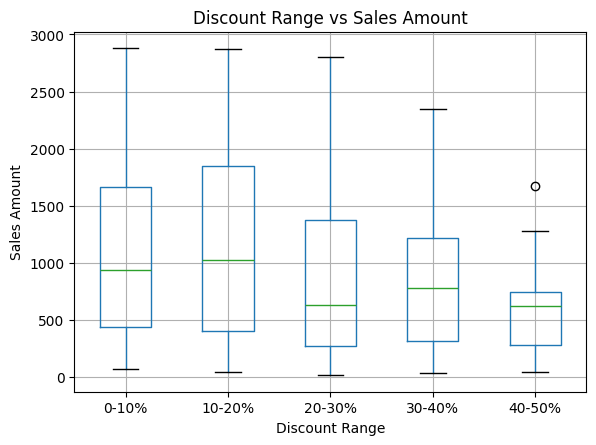

In [89]:
import pandas as pd
import matplotlib.pyplot as plt

df_final['discount_range'] = pd.cut(
    df_final['discount_pct'],
    bins=[-0.01, 0.10, 0.20, 0.30, 0.40, 0.50],
    labels=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%']
)

plt.figure(figsize=(9, 5))

df_final.boxplot(
    column='sales_amount',
    by='discount_range'
)

plt.title('Discount Range vs Sales Amount')
plt.suptitle('')
plt.xlabel('Discount Range')
plt.ylabel('Sales Amount')

plt.show()

#Representing bivariate analysis on a 2*2 sub plot

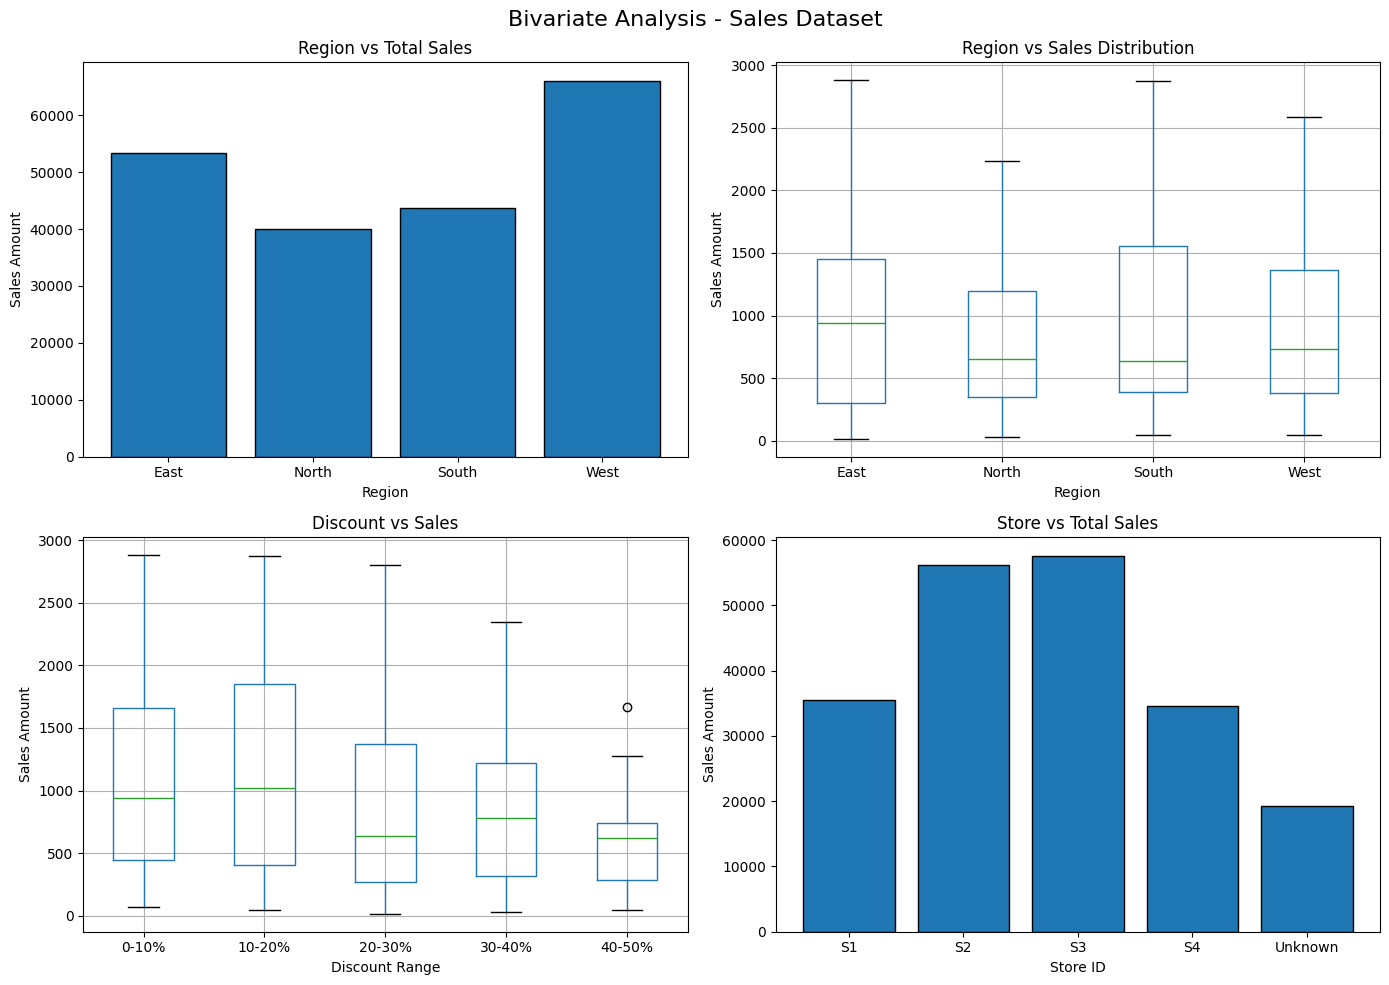

In [90]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Region vs Sales - Bar Chart
region_sales = df_final.groupby('region')['sales_amount'].sum()

axes[0, 0].bar(region_sales.index, region_sales.values, edgecolor='black')
axes[0, 0].set_title('Region vs Total Sales')
axes[0, 0].set_xlabel('Region')
axes[0, 0].set_ylabel('Sales Amount')

# 2. Region vs Sales - Box Plot
df_final.boxplot(
    column='sales_amount',
    by='region',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Region vs Sales Distribution')
axes[0, 1].set_xlabel('Region')
axes[0, 1].set_ylabel('Sales Amount')

# 3. Discount vs Sales - Box Plot
df_final['discount_range'] = pd.cut(
    df_final['discount_pct'],
    bins=[-0.01, 0.10, 0.20, 0.30, 0.40, 0.50],
    labels=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%']
)

df_final.boxplot(
    column='sales_amount',
    by='discount_range',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Discount vs Sales')
axes[1, 0].set_xlabel('Discount Range')
axes[1, 0].set_ylabel('Sales Amount')

# 4. Store vs Sales - Bar Chart
store_sales = df_final.groupby('store_id')['sales_amount'].sum()

axes[1, 1].bar(store_sales.index, store_sales.values, edgecolor='black')
axes[1, 1].set_title('Store vs Total Sales')
axes[1, 1].set_xlabel('Store ID')
axes[1, 1].set_ylabel('Sales Amount')

plt.suptitle('Bivariate Analysis - Sales Dataset', fontsize=16)
plt.tight_layout()
plt.show()

#**Multivariate**

#Heatmap

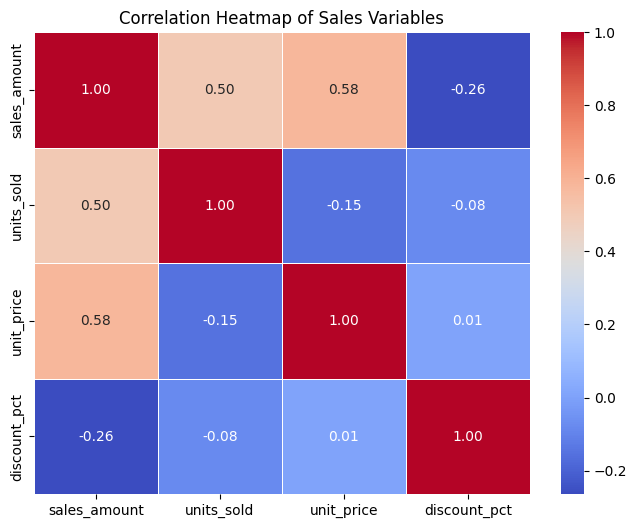

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df_final[
    ['sales_amount', 'units_sold', 'unit_price', 'discount_pct']
]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Sales Variables')
plt.show()

#Pair Plot

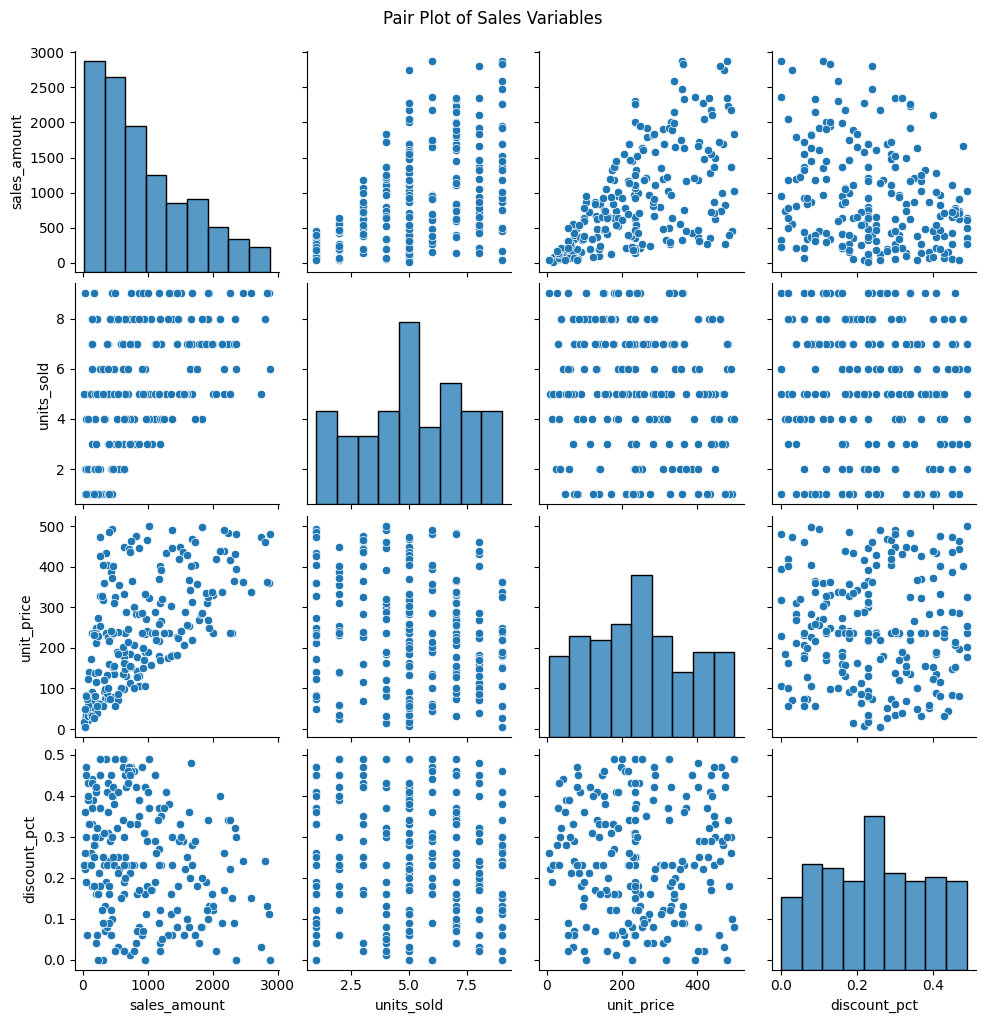

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    df_final[['sales_amount', 'units_sold', 'unit_price', 'discount_pct']],
    diag_kind='hist'
)

plt.suptitle('Pair Plot of Sales Variables', y=1.02)
plt.show()